
# TP3 — Relaciones bivariadas del error meteorológico

**Materia:** Taller de Análisis de Datos I  
**Trabajo Práctico:** N.º 3  
**Etapa:** Análisis exploratorio de relaciones bivariadas

## 1. Introducción

El presente notebook estudia las relaciones entre el error de predicción de temperatura y diferentes variables meteorológicas y geográficas.

El objetivo es identificar patrones, asociaciones y posibles relaciones no lineales que ayuden a explicar el comportamiento de los errores de pronóstico.

Los resultados servirán para fundamentar la selección de variables predictoras y la elección posterior de modelos de Machine Learning.

## 2. Objetivos

- Analizar la relación entre temperatura pronosticada y error.
- Investigar la influencia de humedad, punto de rocío, viento y probabilidad de precipitación.
- Estudiar posibles asociaciones entre ubicación geográfica y error.
- Comparar las relaciones en horizontes de 12 y 24 horas.
- Calcular medidas de asociación e interpretar sus limitaciones.
- Identificar patrones no lineales mediante visualizaciones.
- Justificar la selección de atributos para el modelado posterior.

## 3. Criterios metodológicos

Se utilizarán los archivos CSV originales, excluyendo los días 22 al 26 de octubre de 2026 según la auditoría documentada en el Notebook 00.

El análisis principal utilizará pronósticos de horizontes de 12 y 24 horas, emparejamientos `interval` y registros con ambas temperaturas disponibles.

Se define el error como:

**Error = Temperatura observada − Temperatura pronosticada**

Los valores positivos indican subestimación de la temperatura y los negativos, sobreestimación.

Se utilizarán las observaciones reales para calcular la variable objetivo y evaluar asociaciones, pero no como variables predictoras disponibles anticipadamente.

Las asociaciones observadas no se interpretarán automáticamente como relaciones causales.

Los resultados de este notebook serán exploratorios. La evaluación de modelos se realizará posteriormente mediante separación temporal.


In [1]:

# ==========================================
# 1. LIBRERÍAS Y CONFIGURACIÓN DEL DATASET
# ==========================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Identificar la carpeta del proyecto
DIRECTORIO_ACTUAL = Path.cwd()

rutas_posibles = [
    DIRECTORIO_ACTUAL / "dataset",
    DIRECTORIO_ACTUAL.parent / "dataset"
]

DATASET_DIR = next(
    (ruta for ruta in rutas_posibles if ruta.is_dir()),
    None
)

if DATASET_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta dataset."
    )

# Identificar los CSV originales
archivos = sorted(
    DATASET_DIR.glob("forecast_observation_*.csv")
)

# Excluir el período anómalo
fechas_excluidas = {
    f"forecast_observation_2026_10_{dia:02d}.csv"
    for dia in range(22, 27)
}

archivos_analisis = [
    archivo for archivo in archivos
    if archivo.name not in fechas_excluidas
]

# Verificaciones iniciales
print("Carpeta del dataset:", DATASET_DIR)

print("\nArchivos originales:", len(archivos))
print("Archivos excluidos:", len(archivos) - len(archivos_analisis))
print("Archivos seleccionados:", len(archivos_analisis))

print("\nPrimer archivo:", archivos_analisis[0].name)
print("Último archivo:", archivos_analisis[-1].name)

print("\nEntorno preparado correctamente.")


Carpeta del dataset: c:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\dataset

Archivos originales: 53
Archivos excluidos: 5
Archivos seleccionados: 48

Primer archivo: forecast_observation_2026_09_10.csv
Último archivo: forecast_observation_2026_11_01.csv

Entorno preparado correctamente.


Nos interesan especialmente:

| Variable |	Posible relación con el error |
|----------|----------------------------------|
|Temperatura pronosticada |	Errores diferentes en condiciones frías y cálidas.|
|Humedad relativa pronosticada |	Influencia de condiciones atmosféricas húmedas.|
|Punto de rocío pronosticado |	Relación con el contenido de humedad del aire.|
|Velocidad del viento pronosticada |	Posibles diferencias según las condiciones de ventilación.|
|Probabilidad de precipitación |	Posibles errores asociados con situaciones meteorológicas inestables.|

In [2]:

# ==========================================
# 2. DISPONIBILIDAD DE VARIABLES METEOROLÓGICAS
# ==========================================

variables_predictoras = [
    "temperature_forecast_c",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "precip_probability_forecast_pct"
]

columnas_necesarias = [
    "horizon_target_hours",
    "match_type",
    "temperature_observed_c"
] + variables_predictoras

# Leer solamente las columnas necesarias
archivo_ejemplo = archivos_analisis[0]

df_muestra = pd.read_csv(
    archivo_ejemplo,
    usecols=columnas_necesarias,
    low_memory=False
)

# Seleccionar registros del análisis principal
seleccion = (
    df_muestra["horizon_target_hours"].isin([12, 24])
    & (df_muestra["match_type"] == "interval")
    & df_muestra["temperature_forecast_c"].notna()
    & df_muestra["temperature_observed_c"].notna()
)

df_muestra = df_muestra.loc[seleccion].copy()

# Calcular disponibilidad por variable
disponibilidad = pd.DataFrame({
    "registros_disponibles": df_muestra[
        variables_predictoras
    ].notna().sum(),

    "registros_faltantes": df_muestra[
        variables_predictoras
    ].isna().sum(),

    "disponibilidad_pct": (
        df_muestra[variables_predictoras]
        .notna().mean() * 100
    )
})

print("Archivo:", archivo_ejemplo.name)
print("Registros seleccionados:", len(df_muestra))

print("\nDisponibilidad de variables:")
display(disponibilidad.round(2))

# Identificar registros completos en todas las variables
filas_completas = (
    df_muestra[variables_predictoras]
    .notna().all(axis=1).sum()
)

print("\nRegistros con todas las variables disponibles:")
print(filas_completas)

print("\nPorcentaje de registros completos:")
print(round(filas_completas / len(df_muestra) * 100, 2), "%")


Archivo: forecast_observation_2026_09_10.csv
Registros seleccionados: 16622

Disponibilidad de variables:


,registros_disponibles,registros_faltantes,disponibilidad_pct
temperature_forecast_c,16622,0,100.00
relative_humidity_forecast_pct,16488,134,99.19
dewpoint_forecast_c,16622,0,100.00
wind_speed_forecast_kmh,16622,0,100.00
precip_probability_forecast_pct,16622,0,100.00



Registros con todas las variables disponibles:
16488

Porcentaje de registros completos:
99.19 %


In [3]:

# ==========================================
# 3. PREPARACIÓN DE DATOS PARA ANÁLISIS BIVARIADO
# ==========================================

columnas_bivariadas = [
    "station_id",
    "state",
    "latitude",
    "longitude",
    "target_time_utc",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "precip_probability_forecast_pct"
]

partes = []

for numero, archivo in enumerate(archivos_analisis, start=1):

    # Leer solo las columnas necesarias y por bloques
    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_bivariadas,
        chunksize=150_000,
        low_memory=False
    ):

        # Seleccionar registros del análisis principal
        seleccion = (
            bloque["horizon_target_hours"].isin([12, 24])
            & (bloque["match_type"] == "interval")
            & bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        datos = bloque.loc[seleccion].copy()

        if not datos.empty:
            partes.append(datos)

    # Mostrar avance cada ocho archivos
    if numero % 8 == 0:
        print(f"Archivos procesados: {numero}/48")

# Construir tabla en memoria
if not partes:
    raise ValueError("No se encontraron registros válidos.")

df_bivariado = pd.concat(
    partes,
    ignore_index=True
)

# Liberar la lista intermedia
del partes

# Calcular el error de temperatura
df_bivariado["error_c"] = (
    df_bivariado["temperature_observed_c"]
    - df_bivariado["temperature_forecast_c"]
)

# Resultado general
print("\nRegistros seleccionados:", len(df_bivariado))

print("\nRegistros por horizonte:")
display(
    df_bivariado["horizon_target_hours"]
    .value_counts()
    .sort_index()
)

print("\nDisponibilidad de variables predictoras:")
display(
    (
        df_bivariado[variables_predictoras]
        .notna().mean() * 100
    ).round(2).to_frame("disponibilidad_pct")
)

print("\nMemoria utilizada por la tabla:")
print(
    round(
        df_bivariado.memory_usage(deep=True).sum()
        / (1024 ** 2),
        2
    ),
    "MB"
)


Archivos procesados: 8/48
Archivos procesados: 16/48
Archivos procesados: 24/48
Archivos procesados: 32/48
Archivos procesados: 40/48
Archivos procesados: 48/48

Registros seleccionados: 854009

Registros por horizonte:


horizon_target_hours
12    427009
24    427000
Name: count, dtype: int64


Disponibilidad de variables predictoras:


,disponibilidad_pct
temperature_forecast_c,100.00
relative_humidity_forecast_pct,99.98
dewpoint_forecast_c,100.00
wind_speed_forecast_kmh,100.00
precip_probability_forecast_pct,100.00



Memoria utilizada por la tabla:
123.73 MB


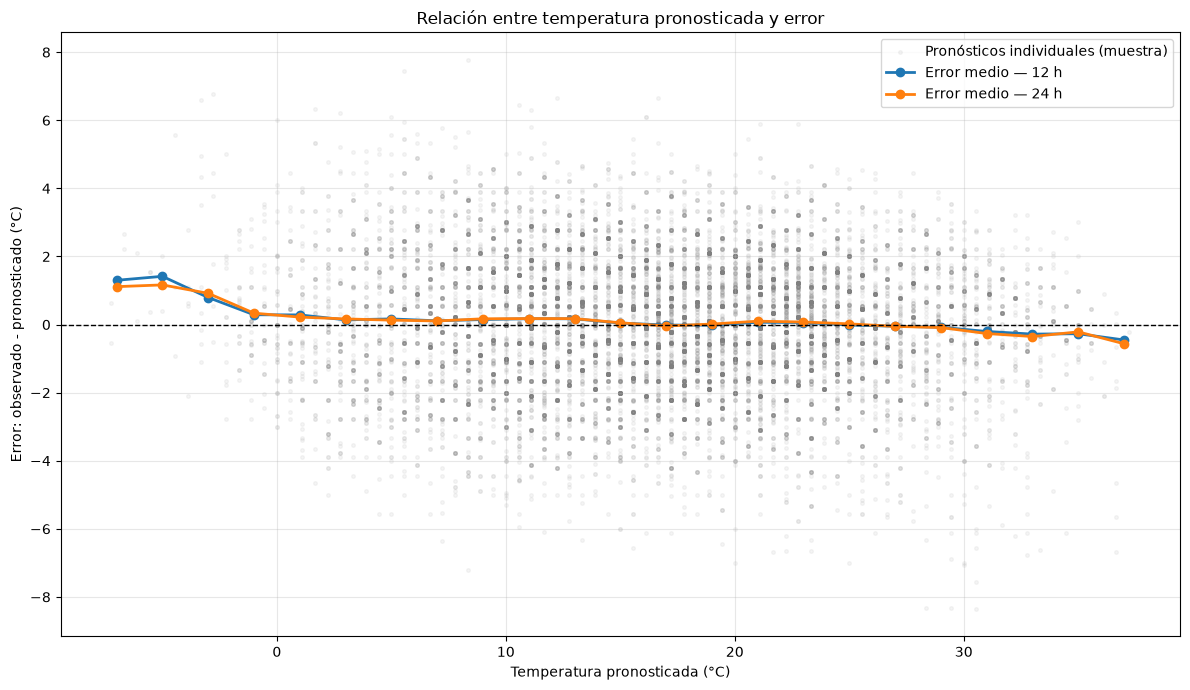

Registros utilizados: 854009

Intervalos con al menos 100 registros:


horizon_target_hours
12    23
24    23
dtype: int64

In [4]:

# ==========================================
# 4. TEMPERATURA PRONOSTICADA VS ERROR
# ==========================================

# Seleccionar variables de interés
columnas_analisis = [
    "temperature_forecast_c",
    "error_c",
    "horizon_target_hours"
]

datos_temp = df_bivariado[
    columnas_analisis
].dropna().copy()

# Muestra reproducible para visualización
muestra_temp = datos_temp.sample(
    n=min(15000, len(datos_temp)),
    random_state=42
)

# Crear intervalos de temperatura de 2 °C
limite_inferior = (
    np.floor(datos_temp["temperature_forecast_c"].min() / 2) * 2
)

limite_superior = (
    np.ceil(datos_temp["temperature_forecast_c"].max() / 2) * 2 + 2
)

intervalos = np.arange(
    limite_inferior,
    limite_superior + 0.01,
    2
)

datos_temp["intervalo_temp"] = pd.cut(
    datos_temp["temperature_forecast_c"],
    bins=intervalos
)

# Error promedio y cantidad por intervalo y horizonte
resumen_temp = (
    datos_temp
    .groupby(
        ["horizon_target_hours", "intervalo_temp"],
        observed=True
    )
    .agg(
        error_medio=("error_c", "mean"),
        registros=("error_c", "size")
    )
    .reset_index()
)

# Punto medio de cada intervalo
resumen_temp["temperatura_centro"] = (
    resumen_temp["intervalo_temp"]
    .apply(lambda x: x.mid)
    .astype(float)
)

# Crear gráfico
fig, ax = plt.subplots(figsize=(12, 7))

# Puntos de la muestra
ax.scatter(
    muestra_temp["temperature_forecast_c"],
    muestra_temp["error_c"],
    s=7,
    alpha=0.08,
    color="gray",
    label="Pronósticos individuales (muestra)"
)

# Curvas por horizonte
for horizonte in [12, 24]:

    datos_h = resumen_temp[
        (resumen_temp["horizon_target_hours"] == horizonte)
        & (resumen_temp["registros"] >= 100)
    ]

    ax.plot(
        datos_h["temperatura_centro"],
        datos_h["error_medio"],
        marker="o",
        linewidth=2,
        label=f"Error medio — {horizonte} h"
    )

# Referencia de error cero
ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Relación entre temperatura pronosticada y error"
)

ax.set_xlabel("Temperatura pronosticada (°C)")
ax.set_ylabel("Error: observado - pronosticado (°C)")

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# Resumen de cantidad de intervalos utilizados
print("Registros utilizados:", len(datos_temp))

print("\nIntervalos con al menos 100 registros:")
display(
    resumen_temp[
        resumen_temp["registros"] >= 100
    ].groupby("horizon_target_hours").size()
)


¿Qué observamos?
1. Temperaturas bajas: aproximadamente por debajo de 0 °C, el error promedio tiende a ser positivo. Es decir, el pronóstico tiende a subestimar la temperatura observada.

2. Temperaturas intermedias: entre aproximadamente 5 y 25 °C, el error promedio se mantiene bastante cerca de cero.

3. Temperaturas altas: a partir de aproximadamente 28–30 °C, aparece una ligera tendencia hacia errores negativos, indicando sobreestimación.

4. Horizontes de 12 y 24 horas: las curvas del error promedio son muy parecidas, aunque anteriormente comprobamos que el MAE global es algo mayor a 24 horas.

5. Dispersión individual: aunque el error promedio sea cercano a cero, hay pronósticos individuales con errores considerables, tanto positivos como negativos.
Resultado principal

El gráfico sugiere que el sesgo medio no es completamente constante: cambia con la temperatura pronosticada y podría presentar una relación no lineal.

In [5]:

# ==========================================
# 5. CORRELACIONES: TEMPERATURA VS ERROR
# ==========================================

resultados_correlacion = []

for horizonte in [12, 24]:

    datos_h = datos_temp[
        datos_temp["horizon_target_hours"] == horizonte
    ]

    pearson = datos_h[
        ["temperature_forecast_c", "error_c"]
    ].corr(method="pearson").iloc[0, 1]

    spearman = datos_h[
        ["temperature_forecast_c", "error_c"]
    ].corr(method="spearman").iloc[0, 1]

    resultados_correlacion.append({
        "horizonte_h": horizonte,
        "registros": len(datos_h),
        "pearson": pearson,
        "spearman": spearman
    })

df_correlacion_temp = pd.DataFrame(
    resultados_correlacion
)

print("Correlaciones por horizonte:")
display(df_correlacion_temp.round(4))

# Cantidades y error promedio según el rango térmico
datos_temp["rango_termico"] = pd.cut(
    datos_temp["temperature_forecast_c"],
    bins=[-np.inf, 0, 10, 20, 30, np.inf],
    labels=[
        "Menos de 0 °C",
        "0 a 10 °C",
        "10 a 20 °C",
        "20 a 30 °C",
        "Más de 30 °C"
    ],
    right=False
)

resumen_rangos = (
    datos_temp
    .groupby(
        ["horizon_target_hours", "rango_termico"],
        observed=True
    )
    .agg(
        registros=("error_c", "size"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_c", lambda x: x.abs().mean())
    )
    .reset_index()
)

print("\nError por rango de temperatura:")
display(resumen_rangos.round(3))


Correlaciones por horizonte:


,horizonte_h,registros,pearson,spearman
0,12,427009,-0.0507,-0.0346
1,24,427000,-0.0491,-0.0310



Error por rango de temperatura:


,horizon_target_hours,rango_termico,registros,sesgo_medio_c,mae_c
0,12,Menos de 0 °C,3980,0.589,1.549
1,12,0 a 10 °C,64586,0.147,1.673
2,12,10 a 20 °C,203229,0.062,1.384
3,12,20 a 30 °C,138013,0.024,1.300
4,12,Más de 30 °C,17201,-0.218,1.259
5,24,Menos de 0 °C,3995,0.669,1.581
6,24,0 a 10 °C,64887,0.141,1.702
7,24,10 a 20 °C,203790,0.066,1.447
8,24,20 a 30 °C,137188,0.043,1.363
9,24,Más de 30 °C,17140,-0.253,1.320


Cuantificar la relación estadística
Vamos a calcular dos coeficientes para cada horizonte:
- Pearson: mide la asociación lineal.
- Spearman: mide la asociación monotónica a partir de rangos y puede detectar tendencias que no sean estrictamente lineales.


### 4.1. Interpretación de temperatura pronosticada y error

Se estudió la relación entre la temperatura pronosticada y el error de predicción, utilizando 854.009 registros de los horizontes de 12 y 24 horas.

Se calcularon los coeficientes de correlación de Pearson y Spearman, y se agruparon las temperaturas en intervalos para estudiar el sesgo medio y el MAE.

**Resultados:**

- Pearson: −0,0507 (12 h) y −0,0491 (24 h).
- Spearman: −0,0346 (12 h) y −0,0310 (24 h).
- Para temperaturas inferiores a 0 °C se observaron sesgos positivos de +0,589 °C y +0,669 °C.
- Para temperaturas de 30 °C o superiores se observaron sesgos negativos de −0,218 °C y −0,253 °C.
- El mayor MAE por rango se registró entre 0 y 10 °C: 1,673 °C (12 h) y 1,702 °C (24 h).

**Interpretación:**

La asociación lineal y monotónica global entre temperatura pronosticada y error es muy débil.

Sin embargo, los promedios por intervalos muestran diferencias en el sesgo según el rango térmico, lo que sugiere un comportamiento que no queda completamente representado por un único coeficiente de correlación.

El MAE también cambia según el rango, alcanzando sus mayores valores en temperaturas de 0 a 10 °C.

**Limitaciones:**

La temperatura pronosticada forma parte del cálculo del error, por lo que la asociación debe interpretarse con cautela.

Además, las diferencias entre rangos podrían estar influidas por la distribución de estaciones, horarios y condiciones meteorológicas.

**Implicancias para el modelado:**

Se conservará la temperatura pronosticada como variable predictora candidata y se evaluará si los modelos no lineales permiten aprovechar los patrones observados.

Su utilidad deberá comprobarse mediante validación temporal, sin asumir que la asociación exploratoria garantiza una mejora predictiva.


In [6]:

# ==========================================
# 6. HUMEDAD RELATIVA PRONOSTICADA VS ERROR
# ==========================================

variable = "relative_humidity_forecast_pct"

# Seleccionar las columnas necesarias
datos_humedad = df_bivariado[
    [variable, "error_c", "horizon_target_hours"]
].dropna().copy()

# Comprobar valores fuera del rango físico esperado
fuera_rango = (
    ~datos_humedad[variable].between(0, 100)
).sum()

print("Registros con humedad fuera de 0–100 %:")
print(fuera_rango)

# Conservar humedades físicamente válidas
datos_humedad = datos_humedad[
    datos_humedad[variable].between(0, 100)
].copy()

# Correlaciones por horizonte
resultados_humedad = []

for horizonte in [12, 24]:

    datos_h = datos_humedad[
        datos_humedad["horizon_target_hours"] == horizonte
    ]

    resultados_humedad.append({
        "horizonte_h": horizonte,
        "registros": len(datos_h),
        "pearson": datos_h[[variable, "error_c"]]
            .corr(method="pearson").iloc[0, 1],
        "spearman": datos_h[[variable, "error_c"]]
            .corr(method="spearman").iloc[0, 1]
    })

print("\nCorrelaciones entre humedad y error:")
display(pd.DataFrame(resultados_humedad).round(4))

# Agrupar humedad en intervalos de 20 puntos porcentuales
datos_humedad["rango_humedad"] = pd.cut(
    datos_humedad[variable],
    bins=[0, 20, 40, 60, 80, 100],
    include_lowest=True,
    labels=["0–20 %", "20–40 %", "40–60 %", "60–80 %", "80–100 %"]
)

# Calcular estadísticas por rango y horizonte
resumen_humedad = (
    datos_humedad
    .groupby(
        ["horizon_target_hours", "rango_humedad"],
        observed=True
    )
    .agg(
        registros=("error_c", "size"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_c", lambda x: x.abs().mean())
    )
    .reset_index()
)

print("\nError según rango de humedad pronosticada:")
display(resumen_humedad.round(3))


Registros con humedad fuera de 0–100 %:
0

Correlaciones entre humedad y error:


,horizonte_h,registros,pearson,spearman
0,12,426941,0.0206,0.0224
1,24,426934,0.0212,0.0210



Error según rango de humedad pronosticada:


,horizon_target_hours,rango_humedad,registros,sesgo_medio_c,mae_c
0,12,0–20 %,51,-0.151,0.981
1,12,20–40 %,18495,0.169,1.125
2,12,40–60 %,75999,0.113,1.379
3,12,60–80 %,123639,-0.107,1.571
4,12,80–100 %,208757,0.122,1.325
5,24,0–20 %,9,0.263,0.831
6,24,20–40 %,16127,0.140,1.158
7,24,40–60 %,76455,0.132,1.399
8,24,60–80 %,123933,-0.104,1.638
9,24,80–100 %,210410,0.129,1.391



### 6.1. Interpretación de humedad relativa y error

Se estudió la relación entre la humedad relativa pronosticada y el error de temperatura para los horizontes de 12 y 24 horas.

**Resultados:**

- Las correlaciones de Pearson fueron +0,0206 (12 h) y +0,0212 (24 h).
- Las correlaciones de Spearman fueron +0,0224 (12 h) y +0,0210 (24 h).
- El mayor MAE entre los intervalos con suficiente representación se registró en el rango de 60–80 % de humedad: 1,571 °C (12 h) y 1,638 °C (24 h).
- El rango de 20–40 % presentó MAE menores: 1,125 °C (12 h) y 1,158 °C (24 h).
- El intervalo de 0–20 % tuvo muy pocas observaciones y sus resultados requieren especial cautela.

**Interpretación:**

No se identifica una asociación lineal o monotónica global fuerte entre humedad relativa pronosticada y error firmado.

Sin embargo, el MAE varía según el rango de humedad, lo que sugiere que podrían existir relaciones no lineales o interacciones con otras condiciones meteorológicas.

La asociación observada no demuestra causalidad y podría estar influida por la temperatura, el horario o las características geográficas de las estaciones.

**Implicancias para el modelado:**

Se mantendrá la humedad relativa pronosticada como variable predictora candidata.

Se evaluará su utilidad mediante validación temporal y comparación de modelos con y sin esta variable.


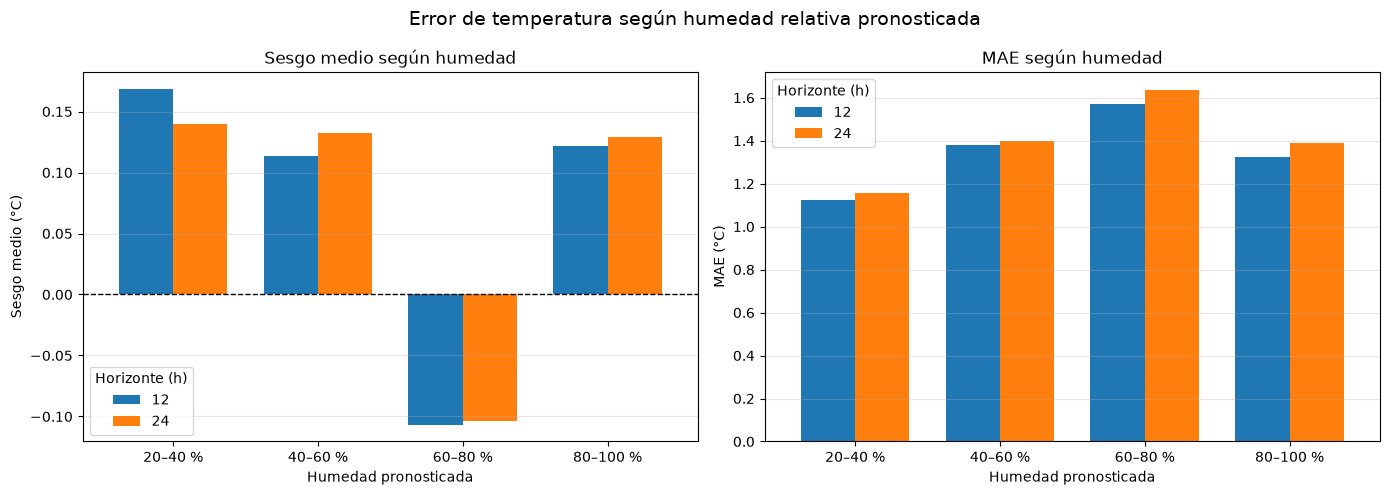

In [7]:

# ==========================================
# 7. SESGO Y MAE SEGÚN HUMEDAD PRONOSTICADA
# ==========================================

# Seleccionar grupos con al menos 100 observaciones
datos_grafico = resumen_humedad[
    resumen_humedad["registros"] >= 100
].copy()

# Ordenar categorías de humedad
orden_humedad = [
    "20–40 %",
    "40–60 %",
    "60–80 %",
    "80–100 %"
]

# Crear tablas para graficar
tabla_sesgo = datos_grafico.pivot(
    index="rango_humedad",
    columns="horizon_target_hours",
    values="sesgo_medio_c"
).reindex(orden_humedad)

tabla_mae = datos_grafico.pivot(
    index="rango_humedad",
    columns="horizon_target_hours",
    values="mae_c"
).reindex(orden_humedad)

# Dos paneles complementarios
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Gráfico del sesgo
tabla_sesgo.plot(
    kind="bar",
    ax=axes[0],
    width=0.75
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title("Sesgo medio según humedad")
axes[0].set_xlabel("Humedad pronosticada")
axes[0].set_ylabel("Sesgo medio (°C)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(title="Horizonte (h)")

# Gráfico del MAE
tabla_mae.plot(
    kind="bar",
    ax=axes[1],
    width=0.75
)

axes[1].set_title("MAE según humedad")
axes[1].set_xlabel("Humedad pronosticada")
axes[1].set_ylabel("MAE (°C)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(title="Horizonte (h)")

fig.suptitle(
    "Error de temperatura según humedad relativa pronosticada",
    fontsize=14
)

plt.tight_layout()
plt.show()


Gráfico izquierdo: sesgo medio
El sesgo cambia de signo según el rango de humedad.
- Entre 20 % y 60 %, los valores positivos indican una ligera tendencia a subestimar la temperatura.
- Entre 60 % y 80 %, el sesgo se vuelve negativo, lo que indica una ligera sobreestimación.
- Entre 80 % y 100 %, el sesgo vuelve a ser positivo.

Gráfico derecho: MAE

| Humedad	| MAE 12 h |	MAE 24 h |
|-----------|----------|-------------|
| 20–40 % |	1,125 °C |	1,158 °C |
| 40–60 % | 1,379 °C |	1,399 °C |
| 60–80 % |	1,571 °C |	1,638 °C |
| 80–100 %|	1,325 °C |	1,391 °C |

Esto sugiere una relación no monótona: el error no aumenta continuamente con la humedad. Además, los errores son mayores a 24 horas en los cuatro rangos representados.


### 7.1. Comparación gráfica del sesgo y MAE según humedad

Se compararon el sesgo medio y el MAE de temperatura para diferentes intervalos de humedad relativa pronosticada.

Se representaron únicamente los grupos con al menos 100 observaciones.

**Resultados:**

- El sesgo medio cambia de signo según el intervalo de humedad.
- El rango de 60–80 % presenta sesgo negativo en ambos horizontes.
- El MAE máximo entre los grupos representados aparece en el rango de 60–80 %: 1,571 °C para 12 horas y 1,638 °C para 24 horas.
- El MAE disminuye en el intervalo de 80–100 %.
- En los cuatro intervalos representados, el horizonte de 24 horas presenta un MAE mayor que el de 12 horas.

**Interpretación:**

La relación entre humedad relativa pronosticada y error de temperatura no presenta una tendencia lineal uniforme.

La magnitud del error varía según las condiciones de humedad, lo que justifica investigar posibles relaciones no lineales e interacciones con otras variables meteorológicas.

Estas diferencias son asociaciones descriptivas y no permiten establecer causalidad.

**Implicancias para el modelado:**

Se conservará la humedad relativa pronosticada como variable candidata y se evaluará su contribución mediante modelos y validación temporal.


In [8]:

# ==========================================
# 8. PUNTO DE ROCÍO PRONOSTICADO VS ERROR
# ==========================================

variable = "dewpoint_forecast_c"

# Seleccionar datos disponibles
datos_rocio = df_bivariado[
    [variable, "error_c", "horizon_target_hours"]
].dropna().copy()

# Calcular error absoluto
datos_rocio["error_abs_c"] = (
    datos_rocio["error_c"].abs()
)

# Resumen de la variable
print("Distribución del punto de rocío pronosticado:")

display(
    datos_rocio.groupby("horizon_target_hours")[variable]
    .agg(["count", "min", "median", "max"])
    .round(2)
)

# Correlaciones
resultados_rocio = []

for horizonte in [12, 24]:

    datos_h = datos_rocio[
        datos_rocio["horizon_target_hours"] == horizonte
    ]

    resultados_rocio.append({
        "horizonte_h": horizonte,
        "registros": len(datos_h),
        "pearson_error": datos_h[
            [variable, "error_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error": datos_h[
            [variable, "error_c"]
        ].corr(method="spearman").iloc[0, 1],
        "pearson_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="spearman").iloc[0, 1]
    })

df_correlacion_rocio = pd.DataFrame(
    resultados_rocio
)

print("\nCorrelaciones del punto de rocío:")
display(df_correlacion_rocio.round(4))


Distribución del punto de rocío pronosticado:


,count,min,median,max
horizon_target_hours,,,,
12,427009,-12.22,12.78,27.22
24,427000,-11.67,12.78,27.22



Correlaciones del punto de rocío:


,horizonte_h,registros,pearson_error,spearman_error,pearson_error_abs,spearman_error_abs
0,12,427009,-0.0432,-0.0352,-0.1067,-0.1051
1,24,427000,-0.0411,-0.0322,-0.0918,-0.0938


Interpretación del punto de rocío
1. Distribución de valores

| Indicador |	Horizonte 12 h |	Horizonte 24 h |
|-----------|------------------|-------------------|
| Registros |	427.009 |	427.000|
| Mínimo |	−12,22 °C |	−11,67 °C |
| Mediana |	12,78 °C |	12,78 °C |
| Máximo |	27,22 °C |	27,22 °C |

2. Correlaciones con el error

| Asociación |	12 h |	24 h |
|------------|-------|-------|
| Pearson con error firmado |	−0,0432 |	−0,0411 |
| Spearman con error firmado |	−0,0352 |	−0,0322 |
| Pearson con error absoluto |	−0,1067 |	−0,0918 |
| Spearman con error absoluto|	−0,1051 |	−0,0938 |

In [9]:

# ==========================================
# 9. ERROR SEGÚN INTERVALOS DE PUNTO DE ROCÍO
# ==========================================

# Definir intervalos de 5 °C
intervalos_rocio = np.arange(-15, 35, 5)

datos_rocio["rango_rocio"] = pd.cut(
    datos_rocio["dewpoint_forecast_c"],
    bins=intervalos_rocio,
    include_lowest=True
)

# Resumen estadístico por horizonte e intervalo
resumen_rocio = (
    datos_rocio
    .groupby(
        ["horizon_target_hours", "rango_rocio"],
        observed=True
    )
    .agg(
        registros=("error_c", "size"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_abs_c", "mean")
    )
    .reset_index()
)

print("Error según intervalo de punto de rocío:")
display(resumen_rocio.round(3))

# Identificar intervalos con menos de 100 registros
print("\nIntervalos con menos de 100 registros:")

display(
    resumen_rocio[
        resumen_rocio["registros"] < 100
    ]
)


Error según intervalo de punto de rocío:


,horizon_target_hours,rango_rocio,registros,sesgo_medio_c,mae_c
0,12,"(-15.001, -10.0]",12,1.242,1.593
1,12,"(-10.0, -5.0]",2860,0.308,1.381
2,12,"(-5.0, 0.0]",18257,0.295,1.545
3,12,"(0.0, 5.0]",53596,0.122,1.587
4,12,"(5.0, 10.0]",93218,0.158,1.550
5,12,"(10.0, 15.0]",94138,-0.008,1.331
6,12,"(15.0, 20.0]",105012,-0.045,1.277
7,12,"(20.0, 25.0]",58979,0.033,1.252
8,12,"(25.0, 30.0]",937,-0.030,1.634
9,24,"(-15.001, -10.0]",17,2.461,2.461



Intervalos con menos de 100 registros:


,horizon_target_hours,rango_rocio,registros,sesgo_medio_c,mae_c
0,12,"(-15.001, -10.0]",12,1.241933,1.593400
9,24,"(-15.001, -10.0]",17,2.460524,2.460524



### 9.1. Interpretación del punto de rocío y el error

Se analizó la relación entre el punto de rocío pronosticado y el error de temperatura, considerando los horizontes de 12 y 24 horas.

**Resultados:**

- Las correlaciones con el error firmado fueron débiles y negativas, aproximadamente −0,04.
- Las correlaciones con el error absoluto también fueron negativas, con valores próximos a −0,10.
- Entre 0 y 10 °C de punto de rocío se observaron errores absolutos relativamente elevados.
- Entre 10 y 25 °C, el MAE disminuyó progresivamente en ambos horizontes.
- Entre 25 y 30 °C, el MAE volvió a aumentar, aunque con una cantidad de registros considerablemente menor.
- El intervalo entre −15 y −10 °C presentó únicamente 12 y 17 observaciones, por lo que sus resultados no se consideran representativos de una tendencia general.

**Interpretación:**

La relación entre el punto de rocío y el error de temperatura es débil en términos de correlación global, pero presenta diferencias según los intervalos analizados.

Estas variaciones podrían estar relacionadas con otras condiciones meteorológicas, la temperatura pronosticada y las características de las estaciones.

La evidencia es descriptiva y no demuestra causalidad.

**Implicancias para el modelado:**

Se conservará el punto de rocío pronosticado como variable predictora candidata.

Su aporte deberá evaluarse mediante validación temporal, considerando también su posible redundancia con la temperatura y la humedad relativa.


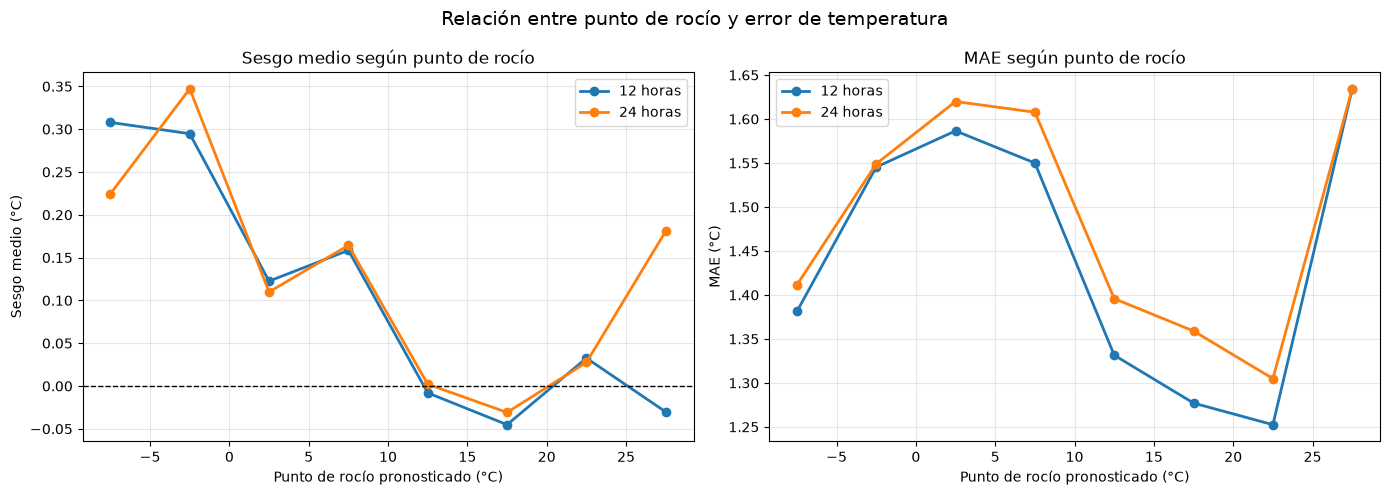

In [10]:

# ==========================================
# 10. GRÁFICOS DEL PUNTO DE ROCÍO Y ERROR
# ==========================================

# Seleccionar intervalos con al menos 100 registros
datos_grafico_rocio = resumen_rocio[
    resumen_rocio["registros"] >= 100
].copy()

# Calcular punto medio de cada intervalo
datos_grafico_rocio["centro_c"] = [
    intervalo.mid
    for intervalo in datos_grafico_rocio["rango_rocio"]
]

# Crear dos gráficos
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for horizonte in [12, 24]:

    datos_h = datos_grafico_rocio[
        datos_grafico_rocio["horizon_target_hours"] == horizonte
    ].sort_values("centro_c")

    # Sesgo medio
    axes[0].plot(
        datos_h["centro_c"],
        datos_h["sesgo_medio_c"],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

    # MAE
    axes[1].plot(
        datos_h["centro_c"],
        datos_h["mae_c"],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

# Línea de referencia del sesgo
axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title("Sesgo medio según punto de rocío")
axes[0].set_ylabel("Sesgo medio (°C)")

axes[1].set_title("MAE según punto de rocío")
axes[1].set_ylabel("MAE (°C)")

for ax in axes:
    ax.set_xlabel("Punto de rocío pronosticado (°C)")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "Relación entre punto de rocío y error de temperatura",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 10.1. Interpretación gráfica del punto de rocío

Se representaron el sesgo medio y el MAE de temperatura según intervalos de 5 °C de punto de rocío pronosticado, comparando los horizontes de 12 y 24 horas.

Se excluyeron de la visualización los intervalos con menos de 100 observaciones.

**Resultados:**

- Los puntos de rocío bajos presentan sesgos medios predominantemente positivos.
- En los intervalos centrales, especialmente entre 10 y 20 °C, el sesgo se aproxima a cero.
- Entre 0 y 25 °C, el MAE muestra una disminución general, aunque no estrictamente uniforme.
- El menor MAE entre los intervalos representados corresponde al rango de 20 a 25 °C.
- Entre 25 y 30 °C el MAE vuelve a aumentar, pero con una cantidad considerablemente menor de registros.

**Interpretación:**

La relación entre el punto de rocío pronosticado y el error de temperatura no es estrictamente lineal.

Los resultados sugieren que esta variable podría aportar información para explicar diferencias en el error, especialmente cuando se combina con otras condiciones meteorológicas.

**Limitaciones:**

El punto de rocío está relacionado con la temperatura y la humedad relativa. Las asociaciones identificadas podrían estar influenciadas por estas variables, así como por factores temporales y geográficos.

La utilidad predictiva del punto de rocío deberá comprobarse mediante validación temporal y comparación de modelos.


In [11]:

# ==========================================
# 11. VELOCIDAD DEL VIENTO PRONOSTICADA VS ERROR
# ==========================================

variable = "wind_speed_forecast_kmh"

# Seleccionar las variables necesarias
datos_viento = df_bivariado[
    [variable, "error_c", "horizon_target_hours"]
].dropna().copy()

# Calcular error absoluto
datos_viento["error_abs_c"] = (
    datos_viento["error_c"].abs()
)

# Verificar velocidades negativas
valores_negativos = (
    datos_viento[variable] < 0
).sum()

print("Velocidades de viento negativas:")
print(valores_negativos)

# Distribución de la velocidad pronosticada
print("\nDistribución de velocidad del viento (km/h):")

display(
    datos_viento
    .groupby("horizon_target_hours")[variable]
    .agg([
        "count",
        "min",
        "median",
        "max",
        lambda x: x.quantile(0.90),
        lambda x: x.quantile(0.99)
    ])
    .rename(columns={
        "<lambda_0>": "percentil_90",
        "<lambda_1>": "percentil_99"
    })
    .round(2)
)

# Correlaciones por horizonte
resultados_viento = []

for horizonte in [12, 24]:

    datos_h = datos_viento[
        datos_viento["horizon_target_hours"] == horizonte
    ]

    resultados_viento.append({
        "horizonte_h": horizonte,
        "registros": len(datos_h),
        "pearson_error": datos_h[
            [variable, "error_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error": datos_h[
            [variable, "error_c"]
        ].corr(method="spearman").iloc[0, 1],
        "pearson_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="spearman").iloc[0, 1]
    })

print("\nCorrelaciones entre viento y error:")

display(
    pd.DataFrame(resultados_viento).round(4)
)


Velocidades de viento negativas:
0

Distribución de velocidad del viento (km/h):


,count,min,median,max,percentil_90,percentil_99
horizon_target_hours,,,,,,
12,427009,0.0,8.05,72.42,20.92,32.19
24,427000,0.0,8.05,72.42,20.92,32.19



Correlaciones entre viento y error:


,horizonte_h,registros,pearson_error,spearman_error,pearson_error_abs,spearman_error_abs
0,12,427009,0.0878,0.1120,-0.0567,-0.0511
1,24,427000,0.0772,0.1051,-0.0427,-0.0374



### 10.1. Interpretación gráfica del punto de rocío

Se representaron el sesgo medio y el MAE de temperatura según intervalos de 5 °C de punto de rocío pronosticado, comparando los horizontes de 12 y 24 horas.

Se excluyeron de la visualización los intervalos con menos de 100 observaciones.

**Resultados:**

- Los puntos de rocío bajos presentan sesgos medios predominantemente positivos.
- En los intervalos centrales, especialmente entre 10 y 20 °C, el sesgo se aproxima a cero.
- Entre 0 y 25 °C, el MAE muestra una disminución general, aunque no estrictamente uniforme.
- El menor MAE entre los intervalos representados corresponde al rango de 20 a 25 °C.
- Entre 25 y 30 °C el MAE vuelve a aumentar, pero con una cantidad considerablemente menor de registros.

**Interpretación:**

La relación entre el punto de rocío pronosticado y el error de temperatura no es estrictamente lineal.

Los resultados sugieren que esta variable podría aportar información para explicar diferencias en el error, especialmente cuando se combina con otras condiciones meteorológicas.

**Limitaciones:**

El punto de rocío está relacionado con la temperatura y la humedad relativa. Las asociaciones identificadas podrían estar influenciadas por estas variables, así como por factores temporales y geográficos.

La utilidad predictiva del punto de rocío deberá comprobarse mediante validación temporal y comparación de modelos.


In [12]:

# ==========================================
# 11. VELOCIDAD DEL VIENTO PRONOSTICADA VS ERROR
# ==========================================

variable = "wind_speed_forecast_kmh"

# Seleccionar las variables necesarias
datos_viento = df_bivariado[
    [variable, "error_c", "horizon_target_hours"]
].dropna().copy()

# Calcular error absoluto
datos_viento["error_abs_c"] = (
    datos_viento["error_c"].abs()
)

# Verificar velocidades negativas
valores_negativos = (
    datos_viento[variable] < 0
).sum()

print("Velocidades de viento negativas:")
print(valores_negativos)

# Distribución de la velocidad pronosticada
print("\nDistribución de velocidad del viento (km/h):")

display(
    datos_viento
    .groupby("horizon_target_hours")[variable]
    .agg([
        "count",
        "min",
        "median",
        "max",
        lambda x: x.quantile(0.90),
        lambda x: x.quantile(0.99)
    ])
    .rename(columns={
        "<lambda_0>": "percentil_90",
        "<lambda_1>": "percentil_99"
    })
    .round(2)
)

# Correlaciones por horizonte
resultados_viento = []

for horizonte in [12, 24]:

    datos_h = datos_viento[
        datos_viento["horizon_target_hours"] == horizonte
    ]

    resultados_viento.append({
        "horizonte_h": horizonte,
        "registros": len(datos_h),
        "pearson_error": datos_h[
            [variable, "error_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error": datos_h[
            [variable, "error_c"]
        ].corr(method="spearman").iloc[0, 1],
        "pearson_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="spearman").iloc[0, 1]
    })

print("\nCorrelaciones entre viento y error:")

display(
    pd.DataFrame(resultados_viento).round(4)
)


Velocidades de viento negativas:
0

Distribución de velocidad del viento (km/h):


,count,min,median,max,percentil_90,percentil_99
horizon_target_hours,,,,,,
12,427009,0.0,8.05,72.42,20.92,32.19
24,427000,0.0,8.05,72.42,20.92,32.19



Correlaciones entre viento y error:


,horizonte_h,registros,pearson_error,spearman_error,pearson_error_abs,spearman_error_abs
0,12,427009,0.0878,0.1120,-0.0567,-0.0511
1,24,427000,0.0772,0.1051,-0.0427,-0.0374


In [14]:

# ==========================================
# 12. ERROR SEGÚN INTERVALOS DE VIENTO
# ==========================================

# Definir los intervalos de velocidad (km/h)
limites_viento = [0, 5, 10, 15, 20, 30, 40, np.inf]

etiquetas_viento = [
    "0–5",
    "5–10",
    "10–15",
    "15–20",
    "20–30",
    "30–40",
    "40 o más"
]

# Clasificar las velocidades pronosticadas
datos_viento["rango_viento"] = pd.cut(
    datos_viento["wind_speed_forecast_kmh"],
    bins=limites_viento,
    labels=etiquetas_viento,
    right=False,
    include_lowest=True
)

# Calcular estadísticas por horizonte e intervalo
resumen_viento = (
    datos_viento
    .groupby(
        ["horizon_target_hours", "rango_viento"],
        observed=True
    )
    .agg(
        registros=("error_c", "size"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_abs_c", "mean")
    )
    .reset_index()
)

print("ERROR SEGÚN INTERVALOS DE VIENTO:")
display(resumen_viento.round(3))

print("\nINTERVALOS CON MENOS DE 100 REGISTROS:")
display(
    resumen_viento[
        resumen_viento["registros"] < 100
    ]
)



ERROR SEGÚN INTERVALOS DE VIENTO:


,horizon_target_hours,rango_viento,registros,sesgo_medio_c,mae_c
0,12,0–5,150985,-0.202,1.458
1,12,5–10,114964,0.103,1.428
2,12,10–15,63116,0.281,1.343
3,12,15–20,52795,0.316,1.329
4,12,20–30,37872,0.234,1.284
5,12,30–40,5488,0.021,1.205
6,12,40 o más,1789,-0.437,1.136
7,24,0–5,152198,-0.180,1.495
8,24,5–10,113867,0.103,1.490
9,24,10–15,63119,0.284,1.416



INTERVALOS CON MENOS DE 100 REGISTROS:


,horizon_target_hours,rango_viento,registros,sesgo_medio_c,mae_c



### 12.1. Interpretación del error según velocidad del viento

Se estudió la relación entre la velocidad del viento pronosticada y el error de temperatura para los horizontes de 12 y 24 horas.

Se definieron intervalos de velocidad desde 0–5 km/h hasta 40 km/h o más.

**Resultados:**

- No se identificaron velocidades negativas.
- La mediana de velocidad fue de 8,05 km/h para ambos horizontes.
- El MAE disminuyó progresivamente entre los intervalos de velocidad estudiados.
- Para 12 horas, el MAE pasó de 1,458 °C (0–5 km/h) a 1,136 °C (40 km/h o más).
- Para 24 horas, el MAE pasó de 1,495 °C a 1,247 °C.
- El sesgo cambió de signo según el intervalo, sin presentar una relación lineal uniforme.
- Todos los intervalos tuvieron más de 100 registros, aunque los vientos más intensos fueron considerablemente menos frecuentes.

**Interpretación:**

La velocidad del viento presenta una asociación negativa débil con el error absoluto de temperatura.

El análisis por intervalos muestra una disminución progresiva del MAE, mientras que el sesgo exhibe un comportamiento no lineal.

Estas asociaciones podrían estar influenciadas por otras condiciones meteorológicas, temporales y geográficas.

**Implicancias para el modelado:**

Se conservará la velocidad del viento pronosticada como variable candidata.

Su contribución se evaluará mediante validación temporal y comparación de modelos, sin interpretar la asociación exploratoria como una relación causal.


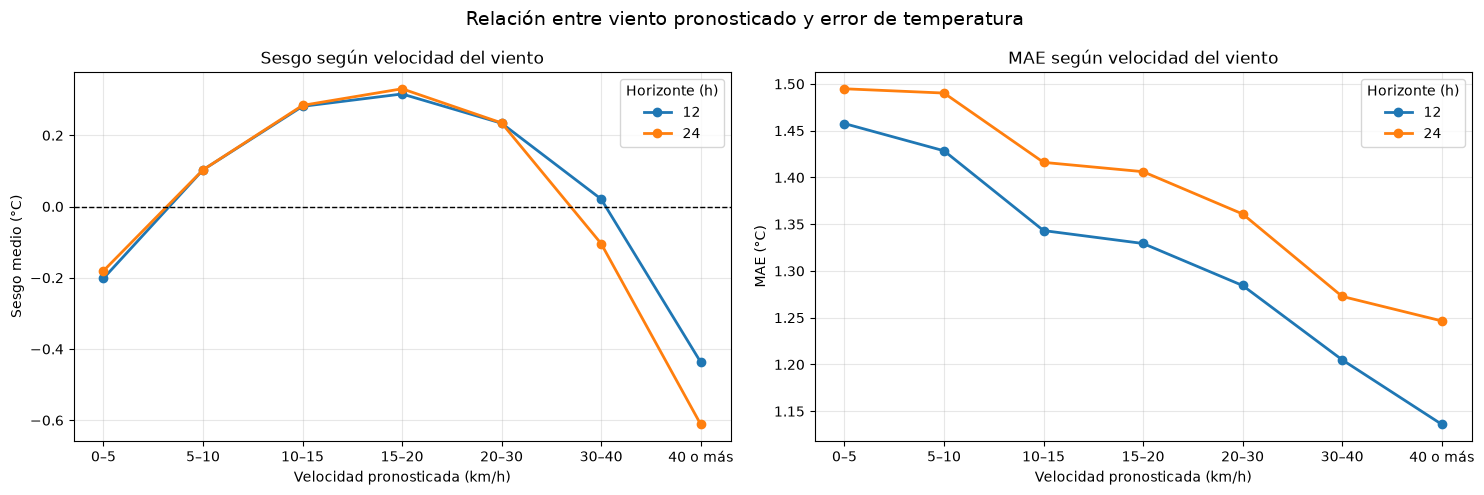

In [15]:

# ==========================================
# 13. GRÁFICOS DE VIENTO Y ERROR
# ==========================================

# Orden de los intervalos
orden_viento = [
    "0–5",
    "5–10",
    "10–15",
    "15–20",
    "20–30",
    "30–40",
    "40 o más"
]

# Preparar tablas
tabla_sesgo_viento = resumen_viento.pivot(
    index="rango_viento",
    columns="horizon_target_hours",
    values="sesgo_medio_c"
).reindex(orden_viento)

tabla_mae_viento = resumen_viento.pivot(
    index="rango_viento",
    columns="horizon_target_hours",
    values="mae_c"
).reindex(orden_viento)

# Crear dos gráficos
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

# Sesgo medio
tabla_sesgo_viento.plot(
    kind="line",
    marker="o",
    linewidth=2,
    ax=axes[0]
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title("Sesgo según velocidad del viento")
axes[0].set_xlabel("Velocidad pronosticada (km/h)")
axes[0].set_ylabel("Sesgo medio (°C)")

# MAE
tabla_mae_viento.plot(
    kind="line",
    marker="o",
    linewidth=2,
    ax=axes[1]
)

axes[1].set_title("MAE según velocidad del viento")
axes[1].set_xlabel("Velocidad pronosticada (km/h)")
axes[1].set_ylabel("MAE (°C)")

# Formato común
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend(title="Horizonte (h)")

fig.suptitle(
    "Relación entre viento pronosticado y error de temperatura",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [16]:

# ==========================================
# 14. PROBABILIDAD DE PRECIPITACIÓN VS ERROR
# ==========================================

variable = "precip_probability_forecast_pct"

# Seleccionar variables necesarias
datos_precipitacion = df_bivariado[
    [variable, "error_c", "horizon_target_hours"]
].dropna().copy()

# Calcular el error absoluto
datos_precipitacion["error_abs_c"] = (
    datos_precipitacion["error_c"].abs()
)

# Verificar el rango físico esperado
fuera_rango = (
    ~datos_precipitacion[variable].between(0, 100)
).sum()

print("Probabilidades fuera de 0–100 %:")
print(fuera_rango)

# Resumen de la distribución
print("\nDistribución de probabilidad de precipitación:")

display(
    datos_precipitacion
    .groupby("horizon_target_hours")[variable]
    .agg(
        count="count",
        minimo="min",
        mediana="median",
        maximo="max",
        percentil_90=lambda x: x.quantile(0.90),
        valores_distintos="nunique"
    )
    .round(2)
)

# Correlaciones por horizonte
resultados_precipitacion = []

for horizonte in [12, 24]:

    datos_h = datos_precipitacion[
        datos_precipitacion["horizon_target_hours"] == horizonte
    ]

    resultados_precipitacion.append({
        "horizonte_h": horizonte,
        "registros": len(datos_h),
        "pearson_error": datos_h[
            [variable, "error_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error": datos_h[
            [variable, "error_c"]
        ].corr(method="spearman").iloc[0, 1],
        "pearson_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="pearson").iloc[0, 1],
        "spearman_error_abs": datos_h[
            [variable, "error_abs_c"]
        ].corr(method="spearman").iloc[0, 1]
    })

print("\nCorrelaciones entre precipitación y error:")

display(
    pd.DataFrame(resultados_precipitacion).round(4)
)


Probabilidades fuera de 0–100 %:
0

Distribución de probabilidad de precipitación:


,count,minimo,mediana,maximo,percentil_90,valores_distintos
horizon_target_hours,,,,,,
12,427009,0.0,1.0,100.0,40.0,101
24,427000,0.0,0.0,100.0,39.0,101



Correlaciones entre precipitación y error:


,horizonte_h,registros,pearson_error,spearman_error,pearson_error_abs,spearman_error_abs
0,12,427009,-0.0533,-0.0058,-0.0382,-0.0805
1,24,427000,-0.0609,-0.0256,-0.0226,-0.0588


In [17]:

# ==========================================
# 15. ERROR SEGÚN PROBABILIDAD DE PRECIPITACIÓN
# ==========================================

# Mantener únicamente probabilidades válidas
datos_precipitacion = datos_precipitacion[
    datos_precipitacion[
        "precip_probability_forecast_pct"
    ].between(0, 100)
].copy()

# Definir intervalos, separando el 0 %
limites_precipitacion = [
    -0.1, 0, 10, 25, 50, 75, 100
]

etiquetas_precipitacion = [
    "0 %",
    ">0–10 %",
    ">10–25 %",
    ">25–50 %",
    ">50–75 %",
    ">75–100 %"
]

datos_precipitacion["rango_precipitacion"] = pd.cut(
    datos_precipitacion[
        "precip_probability_forecast_pct"
    ],
    bins=limites_precipitacion,
    labels=etiquetas_precipitacion,
    include_lowest=True
)

# Agrupar por horizonte y probabilidad
resumen_precipitacion = (
    datos_precipitacion
    .groupby(
        [
            "horizon_target_hours",
            "rango_precipitacion"
        ],
        observed=True
    )
    .agg(
        registros=("error_c", "size"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_abs_c", "mean")
    )
    .reset_index()
)

# Porcentaje de registros dentro de cada horizonte
resumen_precipitacion["porcentaje_registros"] = (
    resumen_precipitacion["registros"]
    / resumen_precipitacion.groupby(
        "horizon_target_hours"
    )["registros"].transform("sum")
    * 100
)

print("ERROR SEGÚN PROBABILIDAD DE PRECIPITACIÓN:")
display(resumen_precipitacion.round(3))

print("\nINTERVALOS CON MENOS DE 100 REGISTROS:")
display(
    resumen_precipitacion[
        resumen_precipitacion["registros"] < 100
    ]
)

print("\nCONTROL DE REGISTROS POR HORIZONTE:")
display(
    resumen_precipitacion.groupby(
        "horizon_target_hours"
    )["registros"].sum()
)


ERROR SEGÚN PROBABILIDAD DE PRECIPITACIÓN:


,horizon_target_hours,rango_precipitacion,registros,sesgo_medio_c,mae_c,porcentaje_registros
0,12,0 %,199059,0.029,1.499,46.617
1,12,>0–10 %,132078,0.207,1.312,30.931
2,12,>10–25 %,35305,0.073,1.256,8.268
3,12,>25–50 %,28580,-0.124,1.326,6.693
4,12,>50–75 %,18949,-0.290,1.388,4.438
5,12,>75–100 %,13038,-0.204,1.260,3.053
6,24,0 %,240033,0.085,1.516,56.214
7,24,>0–10 %,93496,0.178,1.353,21.896
8,24,>10–25 %,33255,0.072,1.366,7.788
9,24,>25–50 %,29230,-0.103,1.425,6.845



INTERVALOS CON MENOS DE 100 REGISTROS:


,horizon_target_hours,rango_precipitacion,registros,sesgo_medio_c,mae_c,porcentaje_registros



CONTROL DE REGISTROS POR HORIZONTE:


horizon_target_hours
12    427009
24    427000
Name: registros, dtype: int64


### 15.1. Interpretación de la probabilidad de precipitación

Se estudió la relación entre la probabilidad de precipitación pronosticada y el error de temperatura, para los horizontes de 12 y 24 horas.

**Resultados:**

- La distribución se concentra fuertemente en probabilidades bajas.
- El 46,62 % de las observaciones a 12 horas y el 56,21 % a 24 horas presentan probabilidad exactamente igual a 0 %.
- Las correlaciones globales con el error firmado y absoluto fueron débiles.
- El grupo con probabilidad 0 % presentó el mayor MAE: 1,499 °C a 12 horas y 1,516 °C a 24 horas.
- El MAE varió de forma no uniforme entre los intervalos.
- El sesgo fue positivo hasta el intervalo >10–25 % y negativo en los intervalos superiores a 25 %.
- El sesgo negativo más pronunciado se observó entre 50 y 75 % de probabilidad.
- Todos los intervalos estuvieron representados por más de 100 observaciones.

**Interpretación:**

La probabilidad de precipitación presenta asociaciones débiles con el error a nivel global, pero permite distinguir grupos con comportamientos diferentes.

El cambio de signo del sesgo y las variaciones no uniformes del MAE sugieren posibles relaciones no lineales.

La probabilidad pronosticada no debe confundirse con precipitación efectivamente observada.

**Limitaciones e implicancias:**

Las asociaciones podrían estar condicionadas por otras variables meteorológicas, geográficas o temporales.

Se conservará la probabilidad de precipitación como variable predictora candidata, cuya utilidad se comprobará posteriormente mediante validación temporal y comparación de modelos.


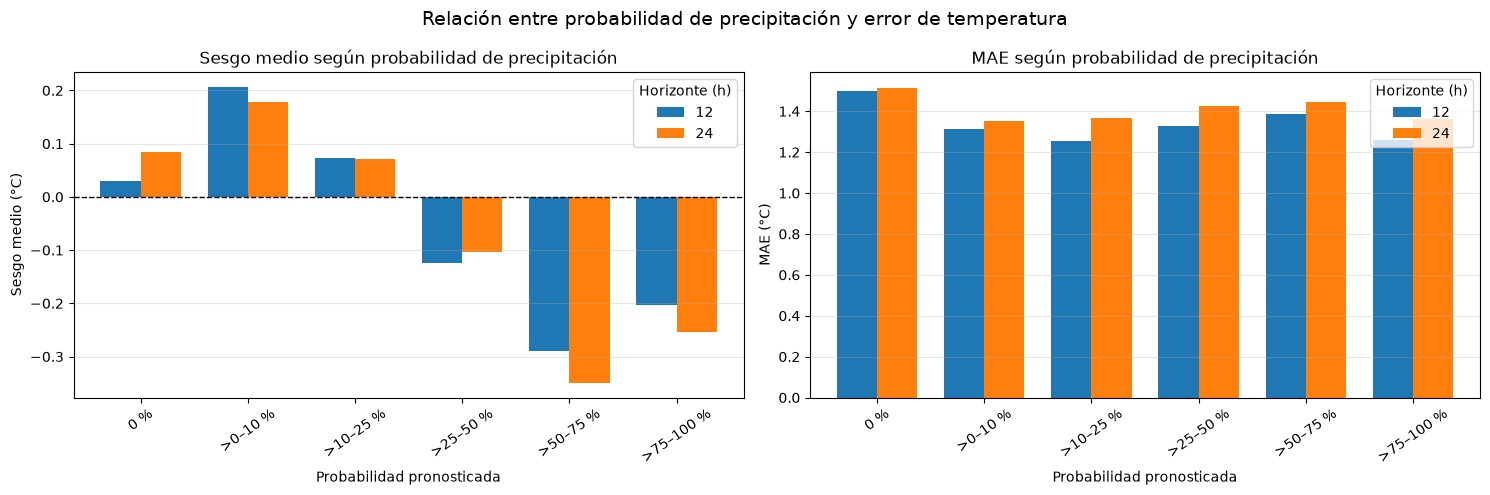

In [18]:

# ==========================================
# 16. GRÁFICOS DE PRECIPITACIÓN Y ERROR
# ==========================================

# Orden de los intervalos
orden_precipitacion = [
    "0 %",
    ">0–10 %",
    ">10–25 %",
    ">25–50 %",
    ">50–75 %",
    ">75–100 %"
]

# Preparar las tablas
tabla_sesgo_prec = resumen_precipitacion.pivot(
    index="rango_precipitacion",
    columns="horizon_target_hours",
    values="sesgo_medio_c"
).reindex(orden_precipitacion)

tabla_mae_prec = resumen_precipitacion.pivot(
    index="rango_precipitacion",
    columns="horizon_target_hours",
    values="mae_c"
).reindex(orden_precipitacion)

# Crear figura con dos paneles
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

# Gráfico del sesgo
tabla_sesgo_prec.plot(
    kind="bar",
    ax=axes[0],
    width=0.75
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    "Sesgo medio según probabilidad de precipitación"
)
axes[0].set_ylabel("Sesgo medio (°C)")
axes[0].set_xlabel("Probabilidad pronosticada")

# Gráfico del MAE
tabla_mae_prec.plot(
    kind="bar",
    ax=axes[1],
    width=0.75
)

axes[1].set_title(
    "MAE según probabilidad de precipitación"
)
axes[1].set_ylabel("MAE (°C)")
axes[1].set_xlabel("Probabilidad pronosticada")

# Formato común
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Horizonte (h)")

fig.suptitle(
    "Relación entre probabilidad de precipitación "
    "y error de temperatura",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [19]:

# ==========================================
# 17. SÍNTESIS DE VARIABLES METEOROLÓGICAS
# ==========================================

variables_meteorologicas = {
    "Temperatura": "temperature_forecast_c",
    "Humedad relativa": "relative_humidity_forecast_pct",
    "Punto de rocío": "dewpoint_forecast_c",
    "Velocidad del viento": "wind_speed_forecast_kmh",
    "Probabilidad de precipitación": "precip_probability_forecast_pct"
}

resultados_comparativos = []

for horizonte in [12, 24]:

    datos_h = df_bivariado[
        df_bivariado["horizon_target_hours"] == horizonte
    ]

    for nombre, columna in variables_meteorologicas.items():

        datos_validos = datos_h[
            [columna, "error_c"]
        ].dropna()

        variable_x = datos_validos[columna]
        error = datos_validos["error_c"]
        error_absoluto = error.abs()

        resultados_comparativos.append({
            "horizonte_h": horizonte,
            "variable": nombre,
            "registros": len(datos_validos),
            "pearson_error": variable_x.corr(
                error, method="pearson"
            ),
            "spearman_error": variable_x.corr(
                error, method="spearman"
            ),
            "pearson_error_abs": variable_x.corr(
                error_absoluto, method="pearson"
            ),
            "spearman_error_abs": variable_x.corr(
                error_absoluto, method="spearman"
            )
        })

df_comparacion_meteorologica = pd.DataFrame(
    resultados_comparativos
)

print("COMPARACIÓN DE VARIABLES METEOROLÓGICAS:")
display(
    df_comparacion_meteorologica.round(4)
)

# Identificar las mayores correlaciones absolutas
# Esto es solo una comparación descriptiva,
# no una medición de importancia predictiva.

df_comparacion_meteorologica["abs_pearson_error"] = (
    df_comparacion_meteorologica[
        "pearson_error"
    ].abs()
)

print("\nCORRELACIONES ABSOLUTAS CON EL ERROR FIRMADO:")
display(
    df_comparacion_meteorologica[
        [
            "horizonte_h",
            "variable",
            "abs_pearson_error"
        ]
    ]
    .sort_values(
        ["horizonte_h", "abs_pearson_error"],
        ascending=[True, False]
    )
    .round(4)
)


COMPARACIÓN DE VARIABLES METEOROLÓGICAS:


,horizonte_h,variable,registros,pearson_error,spearman_error,pearson_error_abs,spearman_error_abs
0,12,Temperatura,427009,-0.0507,-0.0346,-0.1058,-0.1043
1,12,Humedad relativa,426941,0.0206,0.0224,-0.0166,-0.0293
2,12,Punto de rocío,427009,-0.0432,-0.0352,-0.1067,-0.1051
3,12,Velocidad del viento,427009,0.0878,0.1120,-0.0567,-0.0511
4,12,Probabilidad de precipitación,427009,-0.0533,-0.0058,-0.0382,-0.0805
5,24,Temperatura,427000,-0.0491,-0.0310,-0.0947,-0.0974
6,24,Humedad relativa,426934,0.0212,0.0210,-0.0084,-0.0195
7,24,Punto de rocío,427000,-0.0411,-0.0322,-0.0918,-0.0938
8,24,Velocidad del viento,427000,0.0772,0.1051,-0.0427,-0.0374
9,24,Probabilidad de precipitación,427000,-0.0609,-0.0256,-0.0226,-0.0588



CORRELACIONES ABSOLUTAS CON EL ERROR FIRMADO:


,horizonte_h,variable,abs_pearson_error
3,12,Velocidad del viento,0.0878
4,12,Probabilidad de precipitación,0.0533
0,12,Temperatura,0.0507
2,12,Punto de rocío,0.0432
1,12,Humedad relativa,0.0206
8,24,Velocidad del viento,0.0772
9,24,Probabilidad de precipitación,0.0609
5,24,Temperatura,0.0491
7,24,Punto de rocío,0.0411
6,24,Humedad relativa,0.0212


#### Interpretación final de la precipitación

En el gráfico izquierdo vemos que el sesgo cambia de signo:
- Entre 0 % y 25 %: predomina la subestimación de temperatura.
- Por encima de 25 %: predomina la sobreestimación.
- Entre 50 % y 75 %: aparece la sobreestimación media más pronunciada, aproximadamente −0,29 °C a 12 horas y −0,35 °C a 24 horas.

En el gráfico derecho, el MAE presenta un comportamiento diferente:
- La probabilidad exactamente 0 % registra el MAE más alto en ambos horizontes.
- El error disminuye en los intervalos siguientes, pero vuelve a aumentar en algunos rangos intermedios.
- El horizonte de 24 horas presenta un MAE mayor que el de 12 horas en todos los intervalos.

Esto significa que la probabilidad de precipitación puede aportar información útil sobre el comportamiento del error, aunque su relación no sea lineal.

#### Síntesis de las cinco variables meteorológicas
Hasta ahora encontramos:
| Variable |	Asociación exploratoria con el error |	Patrón principal |
|----------|-----------------------------------------|-------------------|
| Temperatura pronosticada |	Débil |	Sesgo diferente entre temperaturas frías y cálidas |
| Humedad relativa |	Muy débil | globalmente	Mayor MAE entre 60 y 80 % |
| Punto de rocío |	Débil, especialmente con error absoluto |	MAE generalmente menor entre 10 y 25 °C|
| Velocidad del viento |	Débil |	MAE decreciente entre los intervalos estudiados |
| Probabilidad de precipitación |	Muy débil globalmente |	Cambio de signo del sesgo por intervalos |

Lo interesante es que ninguna variable explica por sí sola el error de temperatura, pero todas mostraron diferencias entre grupos.

Esto respalda nuestra decisión de explorar modelos que puedan combinar variables y capturar relaciones no lineales.

In [20]:

# ==========================================
# 17. SÍNTESIS DE VARIABLES METEOROLÓGICAS
# ==========================================

variables_meteorologicas = {
    "Temperatura": "temperature_forecast_c",
    "Humedad relativa": "relative_humidity_forecast_pct",
    "Punto de rocío": "dewpoint_forecast_c",
    "Velocidad del viento": "wind_speed_forecast_kmh",
    "Probabilidad de precipitación": "precip_probability_forecast_pct"
}

resultados_comparativos = []

for horizonte in [12, 24]:

    datos_h = df_bivariado[
        df_bivariado["horizon_target_hours"] == horizonte
    ]

    for nombre, columna in variables_meteorologicas.items():

        datos_validos = datos_h[
            [columna, "error_c"]
        ].dropna()

        variable_x = datos_validos[columna]
        error = datos_validos["error_c"]
        error_absoluto = error.abs()

        resultados_comparativos.append({
            "horizonte_h": horizonte,
            "variable": nombre,
            "registros": len(datos_validos),
            "pearson_error": variable_x.corr(
                error, method="pearson"
            ),
            "spearman_error": variable_x.corr(
                error, method="spearman"
            ),
            "pearson_error_abs": variable_x.corr(
                error_absoluto, method="pearson"
            ),
            "spearman_error_abs": variable_x.corr(
                error_absoluto, method="spearman"
            )
        })

df_comparacion_meteorologica = pd.DataFrame(
    resultados_comparativos
)

print("COMPARACIÓN DE VARIABLES METEOROLÓGICAS:")
display(
    df_comparacion_meteorologica.round(4)
)

# Identificar las mayores correlaciones absolutas
# Esto es solo una comparación descriptiva,
# no una medición de importancia predictiva.

df_comparacion_meteorologica["abs_pearson_error"] = (
    df_comparacion_meteorologica[
        "pearson_error"
    ].abs()
)

print("\nCORRELACIONES ABSOLUTAS CON EL ERROR FIRMADO:")
display(
    df_comparacion_meteorologica[
        [
            "horizonte_h",
            "variable",
            "abs_pearson_error"
        ]
    ]
    .sort_values(
        ["horizonte_h", "abs_pearson_error"],
        ascending=[True, False]
    )
    .round(4)
)


COMPARACIÓN DE VARIABLES METEOROLÓGICAS:


,horizonte_h,variable,registros,pearson_error,spearman_error,pearson_error_abs,spearman_error_abs
0,12,Temperatura,427009,-0.0507,-0.0346,-0.1058,-0.1043
1,12,Humedad relativa,426941,0.0206,0.0224,-0.0166,-0.0293
2,12,Punto de rocío,427009,-0.0432,-0.0352,-0.1067,-0.1051
3,12,Velocidad del viento,427009,0.0878,0.1120,-0.0567,-0.0511
4,12,Probabilidad de precipitación,427009,-0.0533,-0.0058,-0.0382,-0.0805
5,24,Temperatura,427000,-0.0491,-0.0310,-0.0947,-0.0974
6,24,Humedad relativa,426934,0.0212,0.0210,-0.0084,-0.0195
7,24,Punto de rocío,427000,-0.0411,-0.0322,-0.0918,-0.0938
8,24,Velocidad del viento,427000,0.0772,0.1051,-0.0427,-0.0374
9,24,Probabilidad de precipitación,427000,-0.0609,-0.0256,-0.0226,-0.0588



CORRELACIONES ABSOLUTAS CON EL ERROR FIRMADO:


,horizonte_h,variable,abs_pearson_error
3,12,Velocidad del viento,0.0878
4,12,Probabilidad de precipitación,0.0533
0,12,Temperatura,0.0507
2,12,Punto de rocío,0.0432
1,12,Humedad relativa,0.0206
8,24,Velocidad del viento,0.0772
9,24,Probabilidad de precipitación,0.0609
5,24,Temperatura,0.0491
7,24,Punto de rocío,0.0411
6,24,Humedad relativa,0.0212


#### Resultado final del análisis

| Hallazgo |	Horizonte 12 h |	Horizonte 24 h |
|----------|-------------------|-------------------|
| Mayor correlación absoluta con el error firmado |	Viento: 0,0878 |	Viento: 0,0772 |
| Mayor correlación absoluta con el MAE individual |	Punto de rocío: 0,1067 |	Temperatura: 0,0947 |
| Correlación más cercana a cero con el error firmado |	Humedad: 0,0206 |	Humedad: 0,0212|

Una precisión: los valores de la segunda fila son correlaciones con el error absoluto de cada observación, no con el MAE agregado.

La conclusión principal es que las correlaciones individuales son débiles, pero observamos patrones por intervalos que justifican investigar relaciones no lineales y combinaciones de variables. No corresponde descartar predictores solo porque tengan correlaciones bajas.